# Preprocesamiento para modelos base multicanal

**Maestría en Inteligencia Artificial MAIA**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

In [1]:
import os
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [2]:
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

DATA_DIR = project_root / "data/sleep-edfx/sleep-cassette" 

In [3]:
from src.data.loader import load_subject, load_psg, find_subject_pairs
from src.data.segmentation import (
    extract_epochs,
    trim_wake_edges,
    EpochDataset,
    concatenate_datasets,
    class_distribution,
    INT_TO_CLASS,
    concatenate_datasets_by_split
)
from src.preprocessing.feature_engineering import extract_features, to_dataframe, FREQ_BANDS

In [4]:
CANALES = ["EEG Fpz-Cz", "EEG Pz-Oz", "EOG horizontal", "EMG submental"]

In [5]:
PSG_PATH = "SC4001E0-PSG.edf"
psg_file = DATA_DIR / PSG_PATH

raw_preview = load_psg(psg_file, verbose=False, canales=CANALES)

def get_channel_sampling_frequencies(raw):
    sampling_freqs = {ch: float(raw.info["sfreq"]) for ch in raw.ch_names}

    try:
        edf_header = raw._raw_extras[0]
        n_samps = np.asarray(edf_header.get("n_samps"), dtype=float)
        record_length = edf_header.get("record_length")
        record_duration = float(np.ravel(record_length)[0])
        sel = edf_header.get("sel", np.arange(len(n_samps)))
        n_samps = n_samps[sel]

        if len(n_samps) == len(raw.ch_names) and record_duration > 0:
            sampling_freqs = {
                ch: float(n_sample / record_duration)
                for ch, n_sample in zip(raw.ch_names, n_samps)
            }
    except Exception as exc:
        print(f"No se pudo leer la frecuencia por canal del encabezado EDF. Detalle: {exc}")

    return sampling_freqs

channel_sampling_freqs = get_channel_sampling_frequencies(raw_preview)

channels_df = pd.DataFrame({
    "canal": raw_preview.ch_names,
    "tipo": raw_preview.get_channel_types(),
    "frecuencia_hz": [channel_sampling_freqs[ch] for ch in raw_preview.ch_names],
    "n_muestras": [raw_preview.n_times] * len(raw_preview.ch_names),
    "duracion_min": [raw_preview.n_times / raw_preview.info["sfreq"] / 60] * len(raw_preview.ch_names),
})

In [6]:
print(f"Canales encontrados: {len(raw_preview.ch_names)}")
print(f"Frecuencia global reportada por MNE: {raw_preview.info['sfreq']} Hz")
display(channels_df)

Canales encontrados: 4
Frecuencia global reportada por MNE: 100.0 Hz


,canal,tipo,frecuencia_hz,n_muestras,duracion_min
0,EEG Fpz-Cz,eeg,100.0,7950000,1325.0
1,EEG Pz-Oz,eeg,100.0,7950000,1325.0
2,EOG horizontal,eeg,100.0,7950000,1325.0
3,EMG submental,eeg,1.0,7950000,1325.0


In [7]:
HYPNO_PATH = "SC4001EC-Hypnogram.edf"

subject = load_subject(DATA_DIR / PSG_PATH, DATA_DIR / HYPNO_PATH)

epoch_ds = extract_epochs(
    subject.raw, subject.annotations,
    recording_id=subject.subject_id,
    channel_picks=CANALES,
)

print("X (señal cruda) shape:", epoch_ds.X.shape, " (n_epochs, n_channels, n_samples)")
print("Canales:", epoch_ds.channel_names)

[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 79500.0s. Probablemente es la cola '?' de relleno.
X (señal cruda) shape: (2650, 4, 3000)  (n_epochs, n_channels, n_samples)
Canales: ['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'EMG submental']


## Dataset espectral multicanal solo con canales a 100 hz

A partir del flujo de `04_data_preprocessing.ipynb`, se construyen datasets tabulares para las combinaciones de canales que la plataforma debe aceptar. Según la descripción del proyecto, la plataforma debe recibir **al menos uno de los dos canales EEG** (`EEG Fpz-Cz` o `EEG Pz-Oz`), pudiendo usar ambos de forma simultánea, y opcionalmente puede incorporar la señal de `EOG horizontal` y/o la de `EMG submental` para complementar la clasificación.

En esta etapa solo se usan los canales muestreados a **100 Hz** (`EEG Fpz-Cz`, `EEG Pz-Oz` y `EOG horizontal`). El `EMG submental` de Sleep Cassette está a 1 Hz (MNE lo remuestrea a 100 Hz al cargarlo junto a los demás canales, pero no tiene información por encima de 0,5 Hz), así que no tiene sentido extraerle las mismas features espectrales por bandas y se deja por fuera por ahora. Con esto quedan 6 combinaciones válidas:

| Combinación | EEG Fpz-Cz | EEG Pz-Oz | EOG horizontal |
|---|:-:|:-:|:-:|
| `eeg_fpz_cz` | ✓ | | |
| `eeg_pz_oz` | | ✓ | |
| `eeg_fpz_cz__eeg_pz_oz` | ✓ | ✓ | |
| `eeg_fpz_cz__eog_horizontal` | ✓ | | ✓ |
| `eeg_pz_oz__eog_horizontal` | | ✓ | ✓ |
| `eeg_fpz_cz__eeg_pz_oz__eog_horizontal` | ✓ | ✓ | ✓ |

Como las grabaciones locales contienen los tres canales, no se imputan señales crudas ni se descarta ninguna grabación por canales faltantes. En el CSV combinado, las features de los canales que no forman parte de una combinación quedan en `NaN` (XGBoost, LightGBM y los árboles de scikit-learn los manejan de forma nativa) y se acompañan con las columnas `has_eeg_fpz_cz`, `has_eeg_pz_oz`, `has_eog_horizontal` y `channel_combo`. Se conserva un único esquema de dataset para simular la inferencia con cualquiera de las combinaciones anteriores.

**Features por canal:**
- **EEG** (Fpz-Cz y Pz-Oz): las 14 features espectrales de `feature_engineering.py`.
- **EOG horizontal**: solo las 7 de [`docs/propuesta_features_eog.md`](../docs/propuesta_features_eog.md) (variante C de `11_eog_features_validation.ipynb`): 3 espectrales (`beta_power_abs`, `delta_power_abs`, `delta_power_rel`) y 4 en el dominio del tiempo (`p2p_robust`, `hjorth_mobility`, `saccade_count`, `kurtosis`). Las demás features espectrales del EOG se calculan pero se descartan al armar el CSV (`EOG_FEATURES`).


In [8]:
EEG_CHANNELS = ["EEG Fpz-Cz", "EEG Pz-Oz"]
OPTIONAL_CHANNELS = ["EOG horizontal"]
CANDIDATE_CHANNELS = EEG_CHANNELS + OPTIONAL_CHANNELS


def channel_slug(channel: str) -> str:
    return channel.lower().replace(" ", "_").replace("-", "_")


def build_channel_combinations(eeg_channels: list[str], optional_channels: list[str]) -> dict[str, list[str]]:
    """Todas las combinaciones con 1+ canales EEG y 0+ canales opcionales."""
    eeg_subsets = [list(c) for n in range(1, len(eeg_channels) + 1) for c in combinations(eeg_channels, n)]
    optional_subsets = [list(c) for n in range(len(optional_channels) + 1) for c in combinations(optional_channels, n)]
    combos = {}
    for optional in optional_subsets:
        for eeg in eeg_subsets:
            channels = eeg + optional
            combos["__".join(channel_slug(ch) for ch in channels)] = channels
    return combos


CHANNEL_COMBINATIONS = build_channel_combinations(EEG_CHANNELS, OPTIONAL_CHANNELS)
HAS_CHANNEL_COLS = ["has_" + channel_slug(ch) for ch in CANDIDATE_CHANNELS]

TRIM_WAKE_BUFFER_EPOCHS = 60
#SPECTRAL_FILL_VALUE = 0.0

# En test, cada grabación se recorta a un múltiplo de BLOCK_EPOCHS (bloques desde
# el inicio, se descarta el resto final), igual que el dashboard con TinySleepNet,
# para evaluar todos los modelos sobre las mismas épocas.
BLOCK_EPOCHS = 15

# Features del EOG que se conservan (variante C de 11_eog_features_validation.ipynb);
# el resto de las features espectrales del EOG se descarta al armar el CSV.
EOG_FEATURE_PREFIX = "EOG_horizontal__"
EOG_FEATURES = [
    EOG_FEATURE_PREFIX + feature
    for feature in [
        "beta_power_abs",
        "delta_power_abs",
        "delta_power_rel",
        "p2p_robust",
        "hjorth_mobility",
        "saccade_count",
        "kurtosis",
    ]
]

SPLIT_PATH = project_root / "data/SC-subjects-split.xlsx"
PROCESSED_DIR = project_root / "data/processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

split_df = pd.read_excel(SPLIT_PATH)
split_df["subject_code"] = split_df["subject"].astype(str).str.zfill(2)
subject_to_split = dict(zip(split_df["subject_code"], split_df["split"]))

pairs = find_subject_pairs(DATA_DIR)
print(f"{len(pairs)} PSG/Hypnograma encontrados")
print(split_df["split"].value_counts())
print(f"{len(CHANNEL_COMBINATIONS)} combinaciones de canales:")
for combo_name, combo_channels in CHANNEL_COMBINATIONS.items():
    print(f"  {combo_name}: {combo_channels}")

153 PSG/Hypnograma encontrados
split
train    121
test      32
Name: count, dtype: int64
6 combinaciones de canales:
  eeg_fpz_cz: ['EEG Fpz-Cz']
  eeg_pz_oz: ['EEG Pz-Oz']
  eeg_fpz_cz__eeg_pz_oz: ['EEG Fpz-Cz', 'EEG Pz-Oz']
  eeg_fpz_cz__eog_horizontal: ['EEG Fpz-Cz', 'EOG horizontal']
  eeg_pz_oz__eog_horizontal: ['EEG Pz-Oz', 'EOG horizontal']
  eeg_fpz_cz__eeg_pz_oz__eog_horizontal: ['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal']


In [9]:
def subset_epoch_channels(dataset: EpochDataset, channel_names: list[str]) -> EpochDataset:
    """Crea una vista/copia de EpochDataset con un subconjunto ordenado de canales."""
    channel_indices = [dataset.channel_names.index(ch) for ch in channel_names]
    return EpochDataset(
        recording_id=dataset.recording_id,
        subject_code=dataset.subject_code,
        night=dataset.night,
        X=dataset.X[:, channel_indices, :],
        y=dataset.y.copy(),
        recording_ids=dataset.recording_ids.copy(),
        subject_codes=dataset.subject_codes.copy(),
        channel_names=list(channel_names),
        sfreq=dataset.sfreq,
        signal_unit=dataset.signal_unit,
        dropped_epochs=dataset.dropped_epochs,
    )


def trim_to_full_blocks(dataset: EpochDataset, block_epochs: int = BLOCK_EPOCHS) -> EpochDataset:
    """Conserva las primeras épocas que forman bloques completos de `block_epochs`."""
    n_usable = (len(dataset.y) // block_epochs) * block_epochs
    return EpochDataset(
        recording_id=dataset.recording_id,
        subject_code=dataset.subject_code,
        night=dataset.night,
        X=dataset.X[:n_usable],
        y=dataset.y[:n_usable],
        recording_ids=dataset.recording_ids[:n_usable],
        subject_codes=dataset.subject_codes[:n_usable],
        channel_names=dataset.channel_names,
        sfreq=dataset.sfreq,
        signal_unit=dataset.signal_unit,
        dropped_epochs=dataset.dropped_epochs + len(dataset.y) - n_usable,
    )


def add_channel_metadata(df: pd.DataFrame, combo_name: str, channels: list[str], split_name: str) -> pd.DataFrame:
    df = df.copy()
    df["channel_combo"] = combo_name
    df["channel_count"] = len(channels)
    df["split"] = split_name
    df["epoch_idx_in_recording"] = df.groupby("recording_id").cumcount()

    for channel, col in zip(CANDIDATE_CHANNELS, HAS_CHANNEL_COLS):
        df[col] = channel in channels

    return df


def class_counts_as_columns(labels: np.ndarray) -> dict[str, int]:
    counts = pd.Series(labels).value_counts().to_dict()
    return {f"n_{stage}": int(counts.get(stage, 0)) for stage in ["W", "N1", "N2", "N3", "REM"]}


In [10]:
all_combo_dfs = []
summary_rows = []
skipped_rows = []

for psg_path, hypno_path in pairs:
    subj = load_subject(psg_path, hypno_path)
    subject_code = subj.subject_id[3:5]
    split_name = subject_to_split.get(subject_code)

    if split_name is None:
        skipped_rows.append({
            "recording_id": subj.subject_id,
            "reason": "subject_code sin split definido",
        })
        continue

    available_channels = set(subj.raw.ch_names)
    if not any(ch in available_channels for ch in EEG_CHANNELS):
        skipped_rows.append({
            "recording_id": subj.subject_id,
            "reason": f"no tiene ningún canal EEG {EEG_CHANNELS}",
        })
        continue

    usable_base_channels = [ch for ch in CANDIDATE_CHANNELS if ch in available_channels]
    base_epochs = extract_epochs(
        subj.raw,
        subj.annotations,
        recording_id=subj.subject_id,
        channel_picks=usable_base_channels,
    )
    trimmed_epochs = trim_wake_edges(base_epochs, buffer_epochs=TRIM_WAKE_BUFFER_EPOCHS)
    if split_name == "test":
        trimmed_epochs = trim_to_full_blocks(trimmed_epochs)

    for combo_name, combo_channels in CHANNEL_COMBINATIONS.items():
        missing_channels = [ch for ch in combo_channels if ch not in usable_base_channels]
        if missing_channels:
            skipped_rows.append({
                "recording_id": subj.subject_id,
                "channel_combo": combo_name,
                "reason": f"faltan canales: {missing_channels}",
            })
            continue

        combo_epochs = subset_epoch_channels(trimmed_epochs, combo_channels)
        combo_features = extract_features(combo_epochs)
        combo_df = to_dataframe(combo_features)
        combo_df = add_channel_metadata(combo_df, combo_name, combo_channels, split_name)
        all_combo_dfs.append(combo_df)

        summary_rows.append({
            "recording_id": subj.subject_id,
            "subject_code": combo_epochs.subject_code,
            "split": split_name,
            "channel_combo": combo_name,
            "channels": " + ".join(combo_channels),
            "n_channels": len(combo_channels),
            "n_epochs_after_trim": len(combo_epochs.y),
            "dropped_epochs_total": combo_epochs.dropped_epochs,
            **class_counts_as_columns(combo_epochs.y),
        })

if not all_combo_dfs:
    raise ValueError("No se pudo construir ningun dataset multicanal. Revisa canales y split.")

combined_df = pd.concat(all_combo_dfs, ignore_index=True, sort=False)

metadata_cols = [
    "channel_combo",
    "channel_count",
    "split",
    "epoch_idx_in_recording",
    *HAS_CHANNEL_COLS,
    "recording_id",
    "subject_code",
    "y",
]
# Del EOG solo se conservan las features de EOG_FEATURES
feature_cols = sorted([
    col for col in combined_df.columns
    if col not in metadata_cols and (not col.startswith(EOG_FEATURE_PREFIX) or col in EOG_FEATURES)
])
missing_eog_features = set(EOG_FEATURES) - set(feature_cols)
if missing_eog_features:
    raise ValueError(f"extract_features no generó estas features del EOG: {sorted(missing_eog_features)}")
#combined_df[feature_cols] = combined_df[feature_cols].fillna(SPECTRAL_FILL_VALUE)
combined_df = combined_df[metadata_cols + feature_cols]

train_df = combined_df[combined_df["split"] == "train"].reset_index(drop=True)
test_df = combined_df[combined_df["split"] == "test"].reset_index(drop=True)

train_path = PROCESSED_DIR / "train_multicanal.csv"
test_path = PROCESSED_DIR / "test_multicanal.csv"
summary_path = PROCESSED_DIR / "multicanal_dataset_summary.csv"
skipped_path = PROCESSED_DIR / "multicanal_dataset_skipped.csv"

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(summary_path, index=False)

skipped_df = pd.DataFrame(skipped_rows)
if not skipped_df.empty:
    skipped_df.to_csv(skipped_path, index=False)

print("Dataset combinado train:", train_df.shape)
print("Dataset combinado test:", test_df.shape)
print(f"Features: {len(feature_cols)} (EOG: {len(EOG_FEATURES)})")
print("Resumen:", summary_df.shape)
if not skipped_df.empty:
    print("Registros/combinaciones omitidas:", skipped_df.shape)
else:
    print("No se omitieron registros ni combinaciones por canales faltantes.")

display(summary_df.groupby(["split", "channel_combo"])["n_epochs_after_trim"].sum().reset_index())


[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 79500.0s. Probablemente es la cola '?' de relleno.
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 84900.0s. Probablemente es la cola '?' de relleno.
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 84060.0s. Probablemente es la cola '?' de relleno.
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 85500.0s. Probablemente es la cola '?' de relleno.
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 84120.0s. Probablemente es la cola '?' de relleno.
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 82680.0s. Probablemente es la cola '?' de relleno.
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 84600.0s. Probablemente es la cola '?' de relleno.
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 81960.0s. Probablemente es la cola '?' de relleno.
[loader] Aviso: el hypnograma termina en 86400.0s pero e

,split,channel_combo,n_epochs_after_trim
0,test,eeg_fpz_cz,44985
1,test,eeg_fpz_cz__eeg_pz_oz,44985
2,test,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,44985
3,test,eeg_fpz_cz__eog_horizontal,44985
4,test,eeg_pz_oz,44985
5,test,eeg_pz_oz__eog_horizontal,44985
6,train,eeg_fpz_cz,150272
7,train,eeg_fpz_cz__eeg_pz_oz,150272
8,train,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,150272
9,train,eeg_fpz_cz__eog_horizontal,150272


## Validación de datasets multicanal procesados

Esta sección revisa los archivos finales procesados con la totalidad de pacientes: no debe haber sujetos compartidos entre train y test, los CSV deben conservar el esquema esperado y las variables numéricas deben ser legibles. 


In [13]:
VALIDATION_PROCESSED_DIR = project_root / "data/processed"

VALIDATION_FILES = {
    "train": VALIDATION_PROCESSED_DIR / "train_multicanal.csv",
    "test": VALIDATION_PROCESSED_DIR / "test_multicanal.csv",
    "summary": VALIDATION_PROCESSED_DIR / "multicanal_dataset_summary.csv",
}

REQUIRED_METADATA_COLUMNS = {
    "channel_combo",
    "channel_count",
    "split",
    "epoch_idx_in_recording",
    *HAS_CHANNEL_COLS,
    "recording_id",
    "subject_code",
    "y",
}

EXPECTED_LABELS = {"W", "N1", "N2", "N3", "REM"}
EXPECTED_CHANNEL_COMBOS = set(CHANNEL_COMBINATIONS)


def read_metadata(path: Path) -> pd.DataFrame:
    return pd.read_csv(
        path,
        usecols=[
            "subject_code",
            "recording_id",
            "split",
            "y",
            "channel_combo",
            *HAS_CHANNEL_COLS,
        ],
        dtype={"subject_code": "string", "recording_id": "string"},
    )


In [14]:
train_meta = read_metadata(VALIDATION_FILES["train"])
test_meta = read_metadata(VALIDATION_FILES["test"])
summary_df = pd.read_csv(
    VALIDATION_FILES["summary"],
    dtype={"subject_code": "string", "recording_id": "string"},
)

train_subjects = set(train_meta["subject_code"].astype(str).str.zfill(2))
test_subjects = set(test_meta["subject_code"].astype(str).str.zfill(2))

validation_results = {
    "summary_n_rows": summary_df.groupby("split")["n_epochs_after_trim"].sum().to_dict(),
    "summary_subjects": summary_df.groupby("split")["subject_code"].nunique().to_dict(),
    "n_total_subjects": len(train_subjects | test_subjects),
    "sumary_dist_subjects": summary_df.groupby("split")["subject_code"].nunique().div(summary_df["subject_code"].nunique()).round(3).to_dict(),
    "summary_recordings": summary_df.groupby("split")["recording_id"].nunique().to_dict(),
    "train_channel_combos": train_meta["channel_combo"].value_counts().to_dict(),
    "test_channel_combos": test_meta["channel_combo"].value_counts().to_dict(),
    "summary_rows": len(summary_df),
}

label_order = ["W", "N1", "N2", "N3", "REM"]
label_distribution_df = pd.DataFrame({
    "train": train_meta["y"].value_counts().reindex(label_order, fill_value=0),
    "test": test_meta["y"].value_counts().reindex(label_order, fill_value=0),
})

display(label_distribution_df)

display(pd.DataFrame([validation_results]).T.rename(columns={0: "valor"}))

,train,test
y,,
W,297390,96984
N1,98670,30462
N2,321558,93234
N3,63474,14760
REM,120540,34470


,valor
summary_n_rows,"{'test': 269910, 'train': 901632}"
summary_subjects,"{'test': 16, 'train': 62}"
n_total_subjects,78
sumary_dist_subjects,"{'test': 0.205, 'train': 0.795}"
summary_recordings,"{'test': 32, 'train': 121}"
train_channel_combos,"{'eeg_fpz_cz': 150272, 'eeg_pz_oz': 150272, 'e..."
test_channel_combos,"{'eeg_fpz_cz': 44985, 'eeg_pz_oz': 44985, 'eeg..."
summary_rows,918


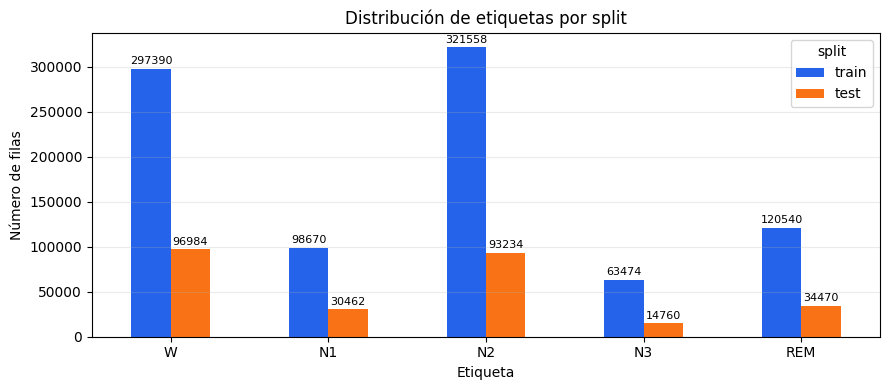

In [15]:
ax = label_distribution_df.plot(
    kind="bar",
    figsize=(9, 4),
    rot=0,
    color=["#2563eb", "#f97316"],
)
ax.set_title("Distribución de etiquetas por split")
ax.set_xlabel("Etiqueta")
ax.set_ylabel("Número de filas")
ax.legend(title="split")
ax.grid(axis="y", alpha=0.25)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", fontsize=8, padding=2)
plt.tight_layout()


## Exploración archivo de entrenamiento

Exploración sencilla de `train_multicanal.csv`: estructura, calidad, distribución de clases, duración de las grabaciones tras el recorte de vigilia y comportamiento de las features. Como cada época aparece una vez por combinación de canales, los análisis de clases y grabaciones se hacen sobre **épocas únicas** (una sola combinación) y los de features sobre la combinación con los 3 canales, para no contar 6 veces la misma época.

### Estructura y calidad

In [16]:
CLASS_ORDER = ["W", "N1", "N2", "N3", "REM"]
FULL_COMBO = "eeg_fpz_cz__eeg_pz_oz__eog_horizontal"

train_eda = pd.read_csv(VALIDATION_FILES["train"], dtype={"subject_code": "string"})

meta_cols = [col for col in train_eda.columns if col in REQUIRED_METADATA_COLUMNS]
feat_cols = [col for col in train_eda.columns if col not in REQUIRED_METADATA_COLUMNS]

print("Filas x columnas:", train_eda.shape)
print(f"Features: {len(feat_cols)}")
print("Duplicados (recording_id, epoch_idx_in_recording, channel_combo):",
      int(train_eda.duplicated(["recording_id", "epoch_idx_in_recording", "channel_combo"]).sum()))
print("Sujetos:", train_eda["subject_code"].nunique(), "| Grabaciones:", train_eda["recording_id"].nunique())
print("Grabaciones por sujeto:",
      train_eda.groupby("subject_code")["recording_id"].nunique().value_counts().sort_index().to_dict())

Filas x columnas: (901632, 45)
Features: 35
Duplicados (recording_id, epoch_idx_in_recording, channel_combo): 0
Sujetos: 62 | Grabaciones: 121
Grabaciones por sujeto: {1: 3, 2: 59}


In [17]:
combo_summary = train_eda.groupby("channel_combo").agg(
    filas=("y", "size"),
    n_canales=("channel_count", "first"),
    **{col: (col, "first") for col in HAS_CHANNEL_COLS},
)
display(combo_summary)

,filas,n_canales,has_eeg_fpz_cz,has_eeg_pz_oz,has_eog_horizontal
channel_combo,,,,,
eeg_fpz_cz,150272,1,True,False,False
eeg_fpz_cz__eeg_pz_oz,150272,2,True,True,False
eeg_fpz_cz__eeg_pz_oz__eog_horizontal,150272,3,True,True,True
eeg_fpz_cz__eog_horizontal,150272,2,True,False,True
eeg_pz_oz,150272,1,False,True,False
eeg_pz_oz__eog_horizontal,150272,2,False,True,True


### Distribución de clases

,epocas,%,horas
y,,,
W,49565,32.98,413.0
N1,16445,10.94,137.0
N2,53593,35.66,446.6
N3,10579,7.04,88.2
REM,20090,13.37,167.4


Ratio clase mayor / menor: 5.07


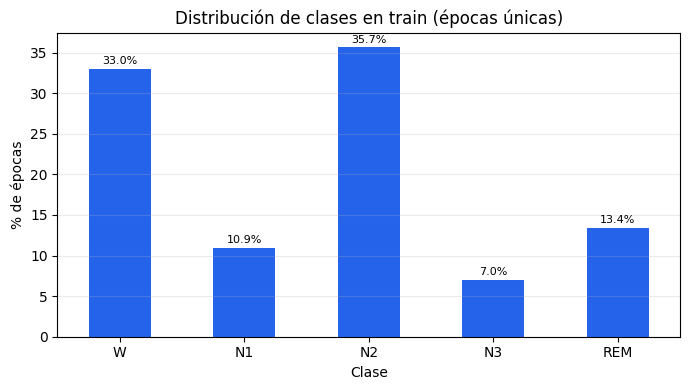

In [18]:
train_epochs = train_eda[train_eda["channel_combo"] == FULL_COMBO]

class_counts = train_epochs["y"].value_counts().reindex(CLASS_ORDER)
class_dist_df = pd.DataFrame({
    "epocas": class_counts,
    "%": (class_counts / class_counts.sum() * 100).round(2),
    "horas": (class_counts * 30 / 3600).round(1),
})
display(class_dist_df)
print("Ratio clase mayor / menor:", round(class_counts.max() / class_counts.min(), 2))

ax = class_dist_df["%"].plot(kind="bar", figsize=(7, 4), rot=0, color="#2563eb")
ax.set_title("Distribución de clases en train (épocas únicas)")
ax.set_xlabel("Clase")
ax.set_ylabel("% de épocas")
ax.grid(axis="y", alpha=0.25)
ax.bar_label(ax.containers[0], fmt="%.1f%%", fontsize=8, padding=2)
plt.tight_layout()
plt.show()

### Grabaciones tras el recorte de vigilia

Épocas por grabación:


,count,mean,std,min,25%,50%,75%,max
epocas,121.0,1241.9,392.2,672.0,1004.0,1099.0,1326.0,2667.0


Horas por grabación: mín 5.6 | mediana 9.2 | máx 22.2
% de cada clase por grabación:


y,W,N1,N2,N3,REM
mean,28.9,10.9,38.2,7.9,14.1
min,12.4,1.4,10.1,0.0,2.1
max,69.9,37.6,60.8,30.9,24.7


Grabaciones sin N3: 13


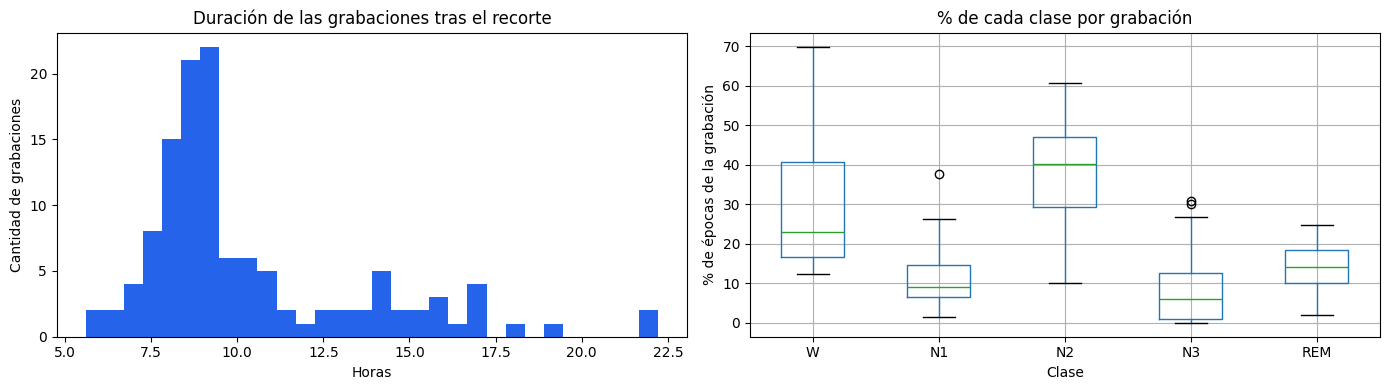

In [19]:
epochs_per_recording = train_epochs.groupby("recording_id").size()
print("Épocas por grabación:")
display(epochs_per_recording.describe().round(1).to_frame("epocas").T)
print("Horas por grabación: mín", round(epochs_per_recording.min() * 30 / 3600, 1),
      "| mediana", round(epochs_per_recording.median() * 30 / 3600, 1),
      "| máx", round(epochs_per_recording.max() * 30 / 3600, 1))

class_pct_by_recording = (
    pd.crosstab(train_epochs["recording_id"], train_epochs["y"], normalize="index")
    .reindex(columns=CLASS_ORDER, fill_value=0) * 100
)
print("% de cada clase por grabación:")
display(class_pct_by_recording.agg(["mean", "min", "max"]).round(1))
print("Grabaciones sin N3:", int((class_pct_by_recording["N3"] == 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(epochs_per_recording * 30 / 3600, bins=30, color="#2563eb")
axes[0].set_title("Duración de las grabaciones tras el recorte")
axes[0].set_xlabel("Horas")
axes[0].set_ylabel("Cantidad de grabaciones")
class_pct_by_recording.boxplot(ax=axes[1])
axes[1].set_title("% de cada clase por grabación")
axes[1].set_xlabel("Clase")
axes[1].set_ylabel("% de épocas de la grabación")
plt.tight_layout()
plt.show()

### Features

In [20]:
CHANNEL_PREFIXES = {"EEG Fpz-Cz": "EEG_Fpz-Cz__", "EEG Pz-Oz": "EEG_Pz-Oz__", "EOG horizontal": "EOG_horizontal__"}
# Features en las que 0 es un valor válido (p. ej. épocas sin sacadas)
ZERO_VALID_FEATURES = {"EOG_horizontal__saccade_count"}

fill_rows = []
for channel, has_col in zip(CANDIDATE_CHANNELS, HAS_CHANNEL_COLS):
    cols = [col for col in feat_cols if col.startswith(CHANNEL_PREFIXES[channel])]
    absent = train_eda.loc[~train_eda[has_col], cols]
    present = train_eda.loc[train_eda[has_col], cols]
    zero_checked = [col for col in cols if col not in ZERO_VALID_FEATURES]
    fill_rows.append({
        "canal": channel,
        "filas_sin_canal": len(absent),
        #"todas_en_0_sin_canal": bool((absent == 0).all().all()),
        "todas_nan_sin_canal": bool(absent.isna().all().all()),
        "nan_con_canal_presente": int(present.isna().sum().sum()),
        "ceros_con_canal_presente": int((present[zero_checked] == 0).sum().sum()),
    })
display(pd.DataFrame(fill_rows))

,canal,filas_sin_canal,todas_nan_sin_canal,nan_con_canal_presente,ceros_con_canal_presente
0,EEG Fpz-Cz,300544,True,0,0
1,EEG Pz-Oz,300544,True,0,0
2,EOG horizontal,450816,True,0,0


In [21]:
train_full = train_eda[train_eda["channel_combo"] == FULL_COMBO]

feature_stats = train_full[feat_cols].describe(percentiles=[0.25, 0.50, 0.70, 0.80, 0.90, 0.95, 0.98, 0.99]).T
feature_stats["skew"] = train_full[feat_cols].skew()
display(feature_stats.round(3))

,count,mean,std,min,25%,50%,70%,80%,90%,95%,98%,99%,max,skew
EEG_Fpz-Cz__alpha_power_abs,150272.0,8.277,10.541,0.056,2.850,5.151,8.511,11.439,17.282,24.641,37.610,51.192,333.200,5.463
EEG_Fpz-Cz__alpha_power_rel,150272.0,0.050,0.048,0.001,0.020,0.036,0.055,0.072,0.102,0.140,0.201,0.249,0.543,2.851
EEG_Fpz-Cz__beta_power_abs,150272.0,11.529,35.683,0.128,1.509,3.153,6.357,10.608,23.302,44.822,92.234,142.083,1191.868,10.705
EEG_Fpz-Cz__beta_power_rel,150272.0,0.052,0.071,0.000,0.011,0.025,0.051,0.078,0.134,0.197,0.288,0.359,0.650,2.859
EEG_Fpz-Cz__delta_alpha_ratio,150272.0,33.532,38.437,0.192,10.803,21.320,36.332,49.698,75.026,102.887,148.905,185.002,1652.829,4.160
EEG_Fpz-Cz__delta_power_abs,150272.0,209.024,302.100,1.074,46.963,106.080,204.894,309.325,519.515,728.138,1030.939,1322.898,6066.948,5.142
EEG_Fpz-Cz__delta_power_rel,150272.0,0.750,0.154,0.082,0.675,0.784,0.849,0.880,0.913,0.932,0.948,0.957,0.994,-1.191
EEG_Fpz-Cz__sef95,150272.0,12.685,6.645,1.000,7.250,11.500,15.000,19.000,23.250,25.750,27.500,28.000,29.750,0.618
EEG_Fpz-Cz__sigma_power_abs,150272.0,5.347,8.514,0.025,1.472,2.926,5.179,7.203,11.327,16.771,27.812,40.237,309.419,6.985
EEG_Fpz-Cz__sigma_power_rel,150272.0,0.029,0.026,0.000,0.011,0.021,0.034,0.045,0.064,0.082,0.104,0.121,0.415,2.110


In [22]:
EOG_TIME_FEATURES = ("p2p_robust", "hjorth_mobility", "saccade_count", "kurtosis")


def class_medians(channel_prefix: str) -> pd.DataFrame:
    cols = [col for col in feat_cols
            if col.startswith(channel_prefix)
            and ("_rel" in col or "sef95" in col or "entropy" in col or col.endswith(EOG_TIME_FEATURES))]
    return (
        train_full.groupby("y")[cols].median()
        .reindex(CLASS_ORDER)
        .rename(columns=lambda col: col.split("__")[1])
        .round(3)
    )

print("Medianas por clase - EEG Fpz-Cz")
display(class_medians("EEG_Fpz-Cz__"))
print("Medianas por clase - EEG Pz-Oz")
display(class_medians("EEG_Pz-Oz__"))
print("Medianas por clase - EOG horizontal")
display(class_medians("EOG_horizontal__"))

Medianas por clase - EEG Fpz-Cz


,alpha_power_rel,beta_power_rel,delta_power_rel,sef95,sigma_power_rel,spectral_entropy,theta_power_rel
y,,,,,,,
W,0.031,0.055,0.783,15.75,0.019,0.637,0.076
N1,0.057,0.047,0.715,14.50,0.029,0.675,0.103
N2,0.036,0.014,0.794,10.50,0.025,0.635,0.095
N3,0.012,0.003,0.919,4.75,0.006,0.506,0.046
REM,0.047,0.038,0.712,12.75,0.021,0.675,0.130


Medianas por clase - EEG Pz-Oz


,alpha_power_rel,beta_power_rel,delta_power_rel,sef95,sigma_power_rel,spectral_entropy,theta_power_rel
y,,,,,,,
W,0.101,0.117,0.474,21.75,0.051,0.781,0.108
N1,0.082,0.035,0.626,13.25,0.029,0.724,0.156
N2,0.047,0.014,0.730,10.50,0.025,0.671,0.141
N3,0.018,0.004,0.877,6.00,0.008,0.535,0.078
REM,0.083,0.033,0.626,12.75,0.026,0.731,0.174


Medianas por clase - EOG horizontal


,delta_power_rel,hjorth_mobility,kurtosis,p2p_robust,saccade_count
y,,,,,
W,0.901,28.090,1.305,271.866,16.0
N1,0.801,34.058,0.677,85.129,0.0
N2,0.783,36.632,0.740,61.960,0.0
N3,0.907,23.705,0.410,100.948,0.0
REM,0.925,19.531,2.590,142.199,1.0


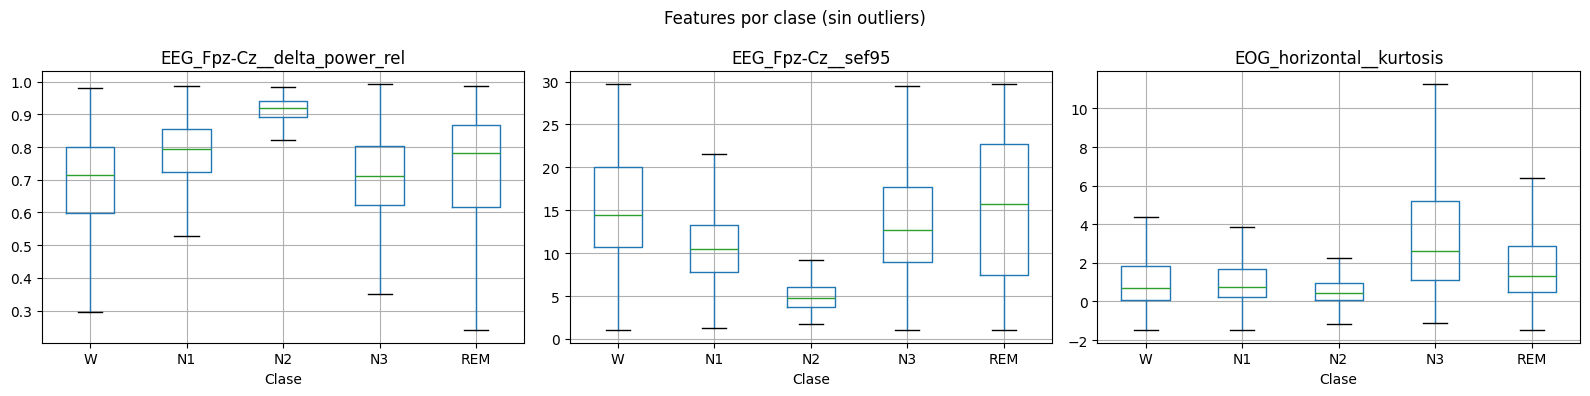

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, feature in zip(axes, ["EEG_Fpz-Cz__delta_power_rel", "EEG_Fpz-Cz__sef95", "EOG_horizontal__kurtosis"]):
    train_full.boxplot(column=feature, by="y", ax=ax, showfliers=False,
                       positions=range(len(CLASS_ORDER)))
    ax.set_xticks(range(len(CLASS_ORDER)), CLASS_ORDER)
    ax.set_title(feature)
    ax.set_xlabel("Clase")
fig.suptitle("Features por clase (sin outliers)")
plt.tight_layout()
plt.show()

In [24]:
feature_corr = train_full[feat_cols].corr().abs()
upper = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool)).stack()
top_corr = upper.sort_values(ascending=False)

print("Pares de features con |corr| > 0.95:", int((top_corr > 0.95).sum()))
display(top_corr.head(10).round(3).to_frame("|corr|"))

Pares de features con |corr| > 0.95: 0


,,|corr|
EEG_Fpz-Cz__delta_power_rel,EEG_Fpz-Cz__spectral_entropy,0.889
EEG_Pz-Oz__beta_power_rel,EEG_Pz-Oz__sef95,0.874
EEG_Fpz-Cz__beta_power_abs,EEG_Fpz-Cz__sigma_power_abs,0.853
EOG_horizontal__delta_power_abs,EOG_horizontal__p2p_robust,0.841
EEG_Fpz-Cz__beta_power_rel,EEG_Fpz-Cz__sef95,0.836
EEG_Pz-Oz__delta_power_rel,EEG_Pz-Oz__spectral_entropy,0.828
EEG_Fpz-Cz__delta_power_rel,EEG_Fpz-Cz__sef95,0.816
EOG_horizontal__p2p_robust,EOG_horizontal__saccade_count,0.811
EEG_Fpz-Cz__alpha_power_abs,EEG_Fpz-Cz__sigma_power_abs,0.807
EEG_Pz-Oz__beta_power_abs,EEG_Pz-Oz__sigma_power_abs,0.806


### Conclusiones de la exploración

- **Datos limpios**: sin nulos, sin valores no finitos ni duplicados; 62 sujetos y 121 grabaciones (59 sujetos con 2 noches y 3 con una).
- **Cada época aparece 6 veces**, una por combinación de canales (150.272 épocas únicas → 901.632 filas). Cualquier validación o búsqueda de hiperparámetros debe separar por `subject_code`, nunca por fila, para que la misma época no quede en entrenamiento y validación con otra combinación.
- **Desbalance de clases**: N2 (35,7 %) y W (33,0 %) dominan y N3 es la clase minoritaria (7,0 %), con una relación de ~5 a 1. Conviene usar pesos por clase y evaluar con F1-macro y matriz de confusión. Además hay mucha variación entre grabaciones y 13 no tienen N3.
- **Recorte de vigilia**: la mediana queda en ~9,2 h por grabación, pero algunas llegan a ~22 h porque tienen sueño en otro momento del día (siestas), que el recorte por bordes no elimina.
- **Canales ausentes en `NaN`**: las features de un canal ausente están siempre en `NaN` y no hay `NaN` cuando el canal está presente, así que el modelo distingue la ausencia del canal de un valor real.
- **Features**: las potencias absolutas tienen fuerte asimetría a la derecha (sin problema para XGBoost; para modelos lineales o redes convendría `log1p`). Las features separan bien las clases: N3 tiene la mayor `delta_power_rel` y el menor `sef95` en EEG, y el EOG ayuda a distinguir REM de N1, que tienen un EEG parecido.
- **Correlación**: solo un par supera |0,95| (potencias absolutas alpha y sigma del EOG); no hay redundancia grave.
- Al evaluar, conviene reportar métricas por `channel_combo` para ver el aporte de cada canal.